# 04. 시계열 연관성 확인 — 샷을 독립 샘플로 봐도 되는가?

**목적**: 2차 파일은 TimeStamp가 빠져 샷을 독립 샘플처럼 다루게 되어 있다. 실제로 **샷 사이에 시간적 연관이 있는지** 데이터로 확인하고,
모델에 시계열 맥락(과거 샷 기반 파생변수)을 넣을 근거가 있는지 판단한다.

| 장 | 질문 | 방법 | 산출물 |
|---|---|---|---|
| 1 | 공정값이 직전 샷과 닮았나? 주기가 있나? | Run 내 자기상관(ACF) + Barrel_4 시차 상관 | `acf_table.csv`, `acf_*.png`, `xcorr_barrel4.png` |
| 2 | 공정값이 Run 안에서 한 방향으로 흘러가나? | Run별 Spearman ρ(값, 샷 순번) | `drift_table.csv`, `drift_*.png` |
| 3 | 불량이 몰려서 나오나? | 연속 불량 수 vs **Run 내 라벨 섞기(순열검정)** | `cluster_test.csv` |
| 4 | 불량이 Run의 특정 위치(재가동 직후 등)에 몰리나? | 위치 구간별 불량률 + Fisher 정확검정 | `position_table.csv` |
| 5 | 불량 **이전**에 공정 신호가 먼저 나타나나? | 이벤트 스터디: 불량 샷 기준 −10~+3샷의 인과적 편차 vs 대조 양품 | `event_*.png`, `event_table.csv` |
| 6 | 종합 판정 | 1~5 결과 요약 | `temporal_summary.csv` |

**데이터**: `base/cn7_shots.csv`, `base/rg3_shots.csv` (split `제외` 빼고), raw 값, **Run 안에서 TimeStamp 순**으로만 비교한다(Run 경계를 넘는 비교 안 함).

## 0. 설정·데이터

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr, fisher_exact

BASE_DIR = './base'
OUT_DIR = './outputs/temporal'
os.makedirs(OUT_DIR, exist_ok=True)
PRODUCTS = ['cn7', 'rg3']
RNG = np.random.default_rng(42)
N_PERM = 5000          # 순열검정 반복 수
TRANSIENT = 5          # 재가동 직후 과도구간(샷 수) — 1장 ACF에서 제외
W, MINP = 20, 5        # 인과적 편차: 직전 20샷 기준, 최소 5샷

_av = {f.name for f in font_manager.fontManager.ttflist}
for _f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if _f in _av:
        mpl.rcParams['font.family'] = _f; break
mpl.rcParams.update({'axes.unicode_minus': False, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5df', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#b5b4ad', 'axes.labelcolor': '#52514e',
                     'xtick.color': '#6f6e69', 'ytick.color': '#6f6e69'})
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 220)

INK, MUTED = '#2b2a27', '#9a998f'
BLUE, RED, ORANGE, PURPLE = '#2a78d6', '#e34948', '#eb6834', '#4a3aa7'
DIVERGING = LinearSegmentedColormap.from_list('div', ['#184f95', '#6da7ec', '#f0efec', '#ef8a88', '#b52a2a'])

D = {}
for p in PRODUCTS:
    df = pd.read_csv(os.path.join(BASE_DIR, f'{p}_shots.csv'), parse_dates=['TimeStamp'])
    df = df[df['split'] != '제외'].sort_values(['run_id', 'TimeStamp']).reset_index(drop=True)
    df['Reason'] = df['Reason'].fillna('정상')
    D[p] = df
VARS = [c[:-4] for c in D['cn7'].columns if c.endswith('_raw')]
raw = lambda c: f'{c}_raw'
short = lambda v: (v.replace('Barrel_Temperature_', 'Barrel_').replace('Mold_Temperature_', 'Mold_')
                    .replace('Hopper_Temperature', 'Hopper').replace('Max_', '').replace('Average_', 'Avg_'))
KEY = ['Max_Injection_Speed', 'Filling_Time', 'Max_Injection_Pressure', 'Max_Switch_Over_Pressure',
       'Cushion_Position', 'Plasticizing_Time', 'Average_Back_Pressure', 'Cycle_Time',
       'Mold_Temperature_3', 'Hopper_Temperature']

def resolution(x):
    # 기록 단위(0.01 / 0.1 등): 고유값 간 최소 간격
    v = np.unique(np.round(pd.Series(x).dropna().values.astype(float), 4))
    if len(v) < 2:
        return np.nan
    return float(np.round(np.min(np.diff(v)), 4))

for p in PRODUCTS:
    d = D[p]
    print(f"{p.upper()}: Run {d['run_id'].nunique()}개, 샷 {len(d)}, 불량 {int(d['PassOrFail'].sum())} "
          f"({d['Reason'].value_counts().drop('정상', errors='ignore').to_dict()})")

CN7: Run 6개, 샷 1979, 불량 20 ({'가스': 11, '초기허용불량': 5, '미성형': 2, '가스+미성형': 2})
RG3: Run 6개, 샷 627, 불량 32 ({'가스': 22, '미성형': 10})


## 1. 공정값 자기상관 (Run 내 ACF)

- 각 Run 안에서 값을 Run 평균으로 중심화한 뒤 **같은 Run 안의 (t, t+k) 쌍만** 모아 상관을 계산 (Run 간 수준 차이가 자기상관으로 잡히지 않게)
- 재가동 직후 `TRANSIENT`샷은 제외 (램프업이 상관을 부풀리는 것 방지)
- **판정**: lag 1 ACF가 95% 무상관 구간(±1.96/√쌍 수)을 벗어나면 "직전 샷과 연관 있음". 값이 사실상 상수인 변수는 `상수`
- 해석: ACF가 크고 천천히 줄면 → **느린 상태 변화**(온도 등) / 음수 골 뒤 다시 양수 봉우리 → **주기적 진동**(히터 제어 on/off 등, 주기 = 봉우리 lag) / lag 1만 크면 → 짧은 관성 / 0 근처 → 샷마다 독립 노이즈

In [2]:
LAGS = list(range(1, 31))

def pooled_acf(d, col, k):
    num = den_a = den_b = 0.0; n = 0
    for _, g in d.groupby('run_id'):
        g = g[g['shots_since_stop'] > TRANSIENT]
        x = g[col].values.astype(float)
        if len(x) <= k + 2:
            continue
        x = x - np.nanmean(x)
        a, b = x[:-k], x[k:]
        m = ~(np.isnan(a) | np.isnan(b))
        num += np.sum(a[m] * b[m]); den_a += np.sum(a[m] ** 2); den_b += np.sum(b[m] ** 2); n += m.sum()
    if den_a == 0 or den_b == 0:
        return np.nan, n
    return num / np.sqrt(den_a * den_b), n

ACF = {}
rows = []
for p in PRODUCTS:
    d = D[p]
    ACF[p] = {}
    for v in VARS:
        vals = [pooled_acf(d, raw(v), k) for k in LAGS]
        acf = np.array([a for a, _ in vals]); n1 = vals[0][1]
        ACF[p][v] = acf
        band = 1.96 / np.sqrt(max(n1, 1))
        period = np.nan
        if np.isnan(acf[0]):
            verdict = '상수'
        elif abs(acf[0]) <= band:
            verdict = '독립(무상관)'
        else:
            # 주기적 진동: 음의 골(< −2·band) 뒤에 양의 봉우리(> 2·band)가 다시 나타남 → 제어 루프 on/off 등
            i_min = int(np.nanargmin(acf[1:15])) + 1
            after = acf[i_min + 1:25]
            if acf[i_min] < -2 * band and len(after) and np.nanmax(after) > 2 * band:
                verdict = '주기적 진동'
                period = LAGS[i_min + 1 + int(np.nanargmax(after))]
            elif np.nanmean(acf[9:20]) > 2 * band:
                verdict = '느린 상태 변화'
            else:
                verdict = '짧은 관성'
        rows.append({'제품': p.upper(), '변수': v, 'lag1': acf[0], 'lag5': acf[4], 'lag10': acf[9], 'lag20': acf[19],
                     '95%구간': band, '판정': verdict, '주기(샷)': period})
ACF_TABLE = pd.DataFrame(rows)
ACF_TABLE.to_csv(f'{OUT_DIR}/acf_table.csv', index=False, encoding='utf-8-sig')
display(ACF_TABLE.pivot(index='변수', columns='제품', values=['lag1', 'lag10', '판정', '주기(샷)']).loc[VARS])

lag1               lag10                  판정           주기(샷)      
제품                             CN7       RG3       CN7       RG3       CN7       RG3   CN7   RG3
변수                                                                                              
Injection_Time            0.689697  0.402669   0.58769  0.036264    주기적 진동     짧은 관성  10.0   NaN
Filling_Time              0.693392  0.458753  0.582776  0.323878    주기적 진동    주기적 진동  10.0   9.0
Plasticizing_Time         0.918733  0.259903  0.252198  0.009385  느린 상태 변화     짧은 관성   NaN   NaN
Cycle_Time                0.183095  0.221872  0.093371 -0.028288     짧은 관성     짧은 관성   NaN   NaN
Clamp_Close_Time          0.824506  0.514782   0.63363  0.111337  느린 상태 변화     짧은 관성   NaN   NaN
Cushion_Position          0.580869  0.439651  0.493194  0.253251  느린 상태 변화    주기적 진동   NaN  18.0
Plasticizing_Position     0.198646  0.172228  0.089765 -0.075439     짧은 관성     짧은 관성   NaN   NaN
Max_Injection_Speed       0.679589  0.572566  0.178446  0.311185     짧은 관성    주기적 진동   NaN  18.0
Max_Screw_RPM             -0.11946 -0.025714  0.055841  0.000689     짧은 관성   독립(무상관)   NaN   NaN
Max_Injection_Pressure    0.569401  0.487325  0.518159  0.220432    주기적 진동    주기적 진동  10.0  17.0
Max_Switch_Over_Pressure  0.529452  0.171948  0.555945  0.082534    주기적 진동     짧은 관성  20.0   NaN
Average_Back_Pressure     0.717327  0.649199  0.638168  0.467347    주기적 진동    주기적 진동  10.0   9.0
Barrel_Temperature_1     -0.006318 -0.019801  0.020245  0.015754   독립(무상관)   독립(무상관)   NaN   NaN
Barrel_Temperature_2      0.009667 -0.296612  0.030393 -0.025355   독립(무상관)     짧은 관성   NaN   NaN
Barrel_Temperature_3     -0.045811  0.041293  0.013435  0.020438     짧은 관성   독립(무상관)   NaN   NaN
Barrel_Temperature_4      0.762624  0.715249  0.814732  0.586988    주기적 진동    주기적 진동  10.0   9.0
Barrel_Temperature_5      0.048792 -0.061785  -0.01205 -0.021503     짧은 관성   독립(무상관)   NaN   NaN
Barrel_Temperature_6      0.181533   0.12066  0.008365 -0.081218     짧은 관성     짧은 관성   NaN   NaN
Hopper_Temperature        0.560878  0.057855  0.559204 -0.035883  느린 상태 변화   독립(무상관)   NaN   NaN
Mold_Temperature_3        0.994666    0.8789  0.976967  0.714554  느린 상태 변화  느린 상태 변화   NaN   NaN
Mold_Temperature_4        0.995313  0.894837  0.976695  0.722257  느린 상태 변화  느린 상태 변화   NaN   NaN

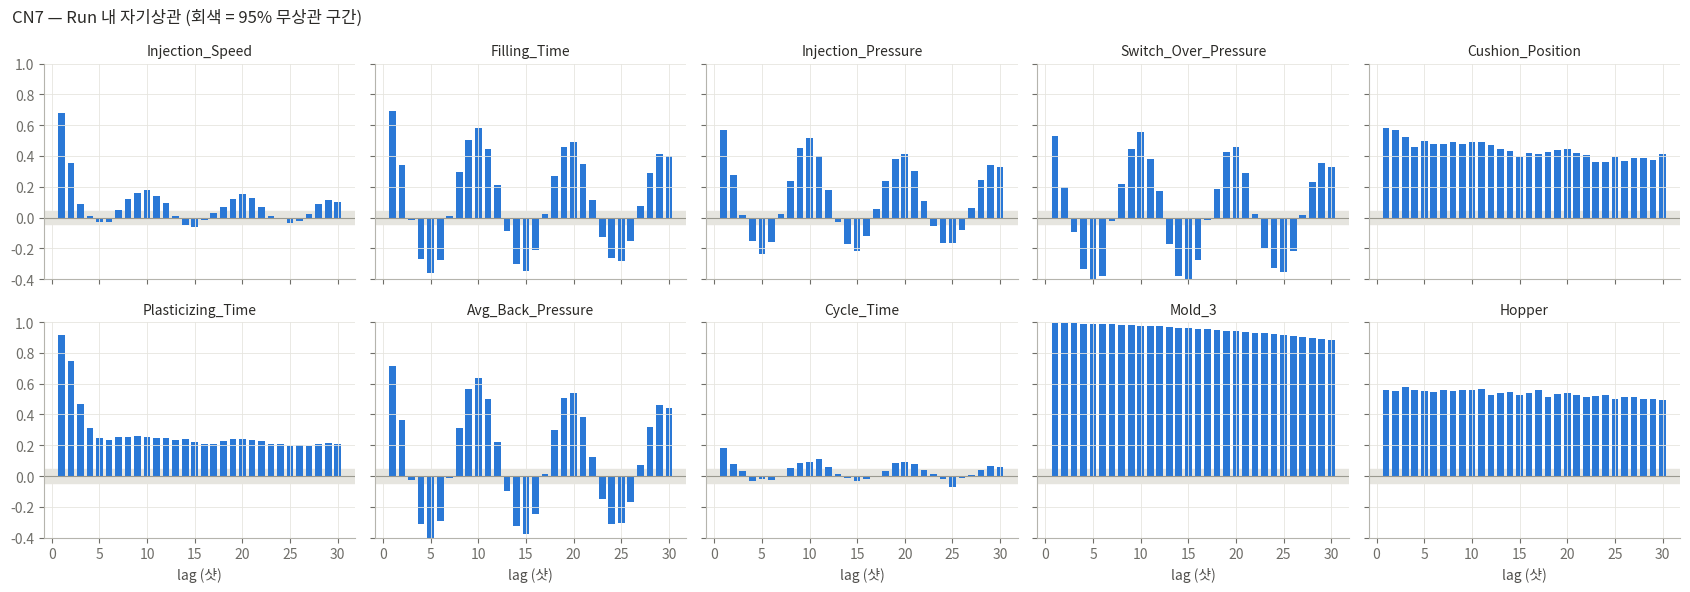

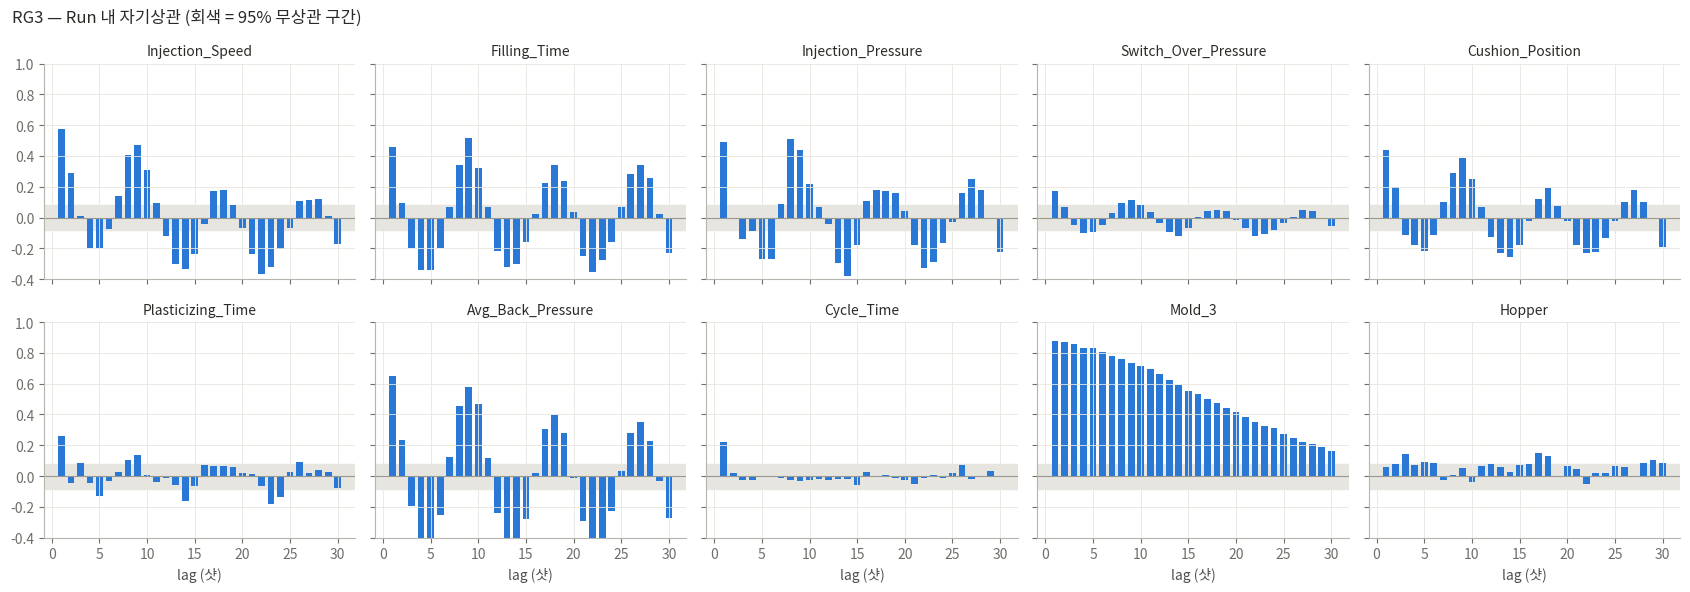

In [3]:
for p in PRODUCTS:
    fig, axes = plt.subplots(2, 5, figsize=(17, 6), sharex=True, sharey=True)
    band = ACF_TABLE.query('제품 == @p.upper()')['95%구간'].iloc[0]
    for ax, v in zip(axes.flat, KEY):
        acf = ACF[p][v]
        ax.axhspan(-band, band, color='#e6e5df', zorder=0)
        ax.axhline(0, color=MUTED, lw=0.8)
        if np.all(np.isnan(acf)):
            ax.text(0.5, 0.5, '상수', transform=ax.transAxes, ha='center', color=MUTED)
        else:
            ax.bar(LAGS, acf, color=BLUE, width=0.7)
        ax.set_title(short(v), fontsize=10, color=INK)
        ax.set_ylim(-0.4, 1.0)
    for ax in axes[1]: ax.set_xlabel('lag (샷)')
    fig.suptitle(f'{p.upper()} — Run 내 자기상관 (회색 = 95% 무상관 구간)', x=0.01, ha='left', color=INK)
    fig.tight_layout(); fig.savefig(f'{OUT_DIR}/acf_{p}.png', dpi=130); plt.show()

### 1-2. 주기적 진동의 원인 후보 — Barrel_4와의 시차 상관

- Barrel_4가 약 9~10샷 주기로 오르내린다(히터 on/off 제어로 추정). 같은 주기로 진동하는 충전·압력 변수와 **시차 상관** `corr(Barrel_4_t, y_{t+L})`을 본다
- L > 0 에서 음의 상관이 가장 크면 → **배럴이 먼저 뜨거워지고 L샷 뒤에 충전시간·압력이 내려감** (용융수지 점도↓ → 충전 빨라짐). 진동 주기 때문에 반대편 L에도 부호가 바뀐 상관이 나타나는 것은 정상

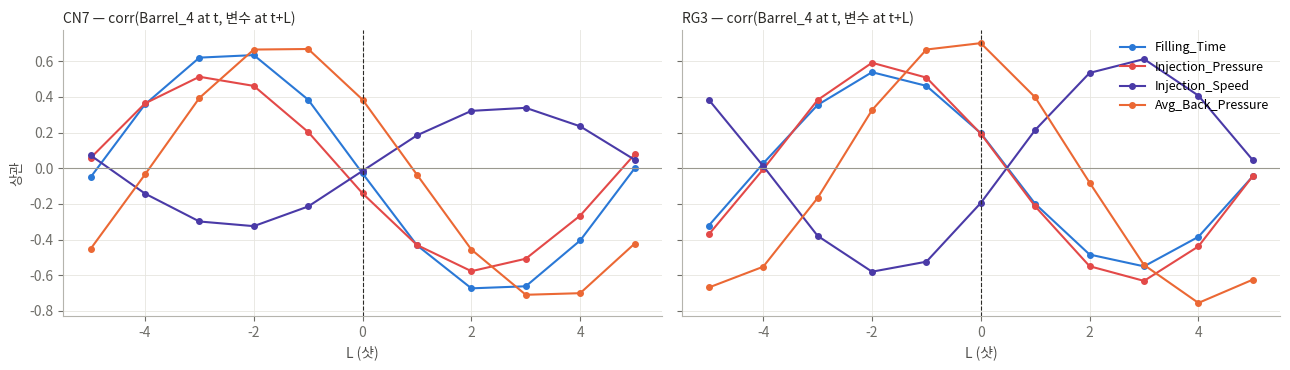

,제품,변수,가장 강한 L(>0),corr
7,CN7,Filling_Time,2,-0.67
18,CN7,Max_Injection_Pressure,2,-0.58
30,CN7,Max_Injection_Speed,3,0.34
41,CN7,Average_Back_Pressure,3,-0.71
52,RG3,Filling_Time,3,-0.55
63,RG3,Max_Injection_Pressure,3,-0.63
74,RG3,Max_Injection_Speed,3,0.61
86,RG3,Average_Back_Pressure,4,-0.76


In [4]:
XC_VARS = ['Filling_Time', 'Max_Injection_Pressure', 'Max_Injection_Speed', 'Average_Back_Pressure']
XL = list(range(-5, 6))
def xcorr(d, xv, yv, L):
    a, b = [], []
    for _, g in d.groupby('run_id'):
        g = g[g['shots_since_stop'] > TRANSIENT]
        x = g[raw(xv)].values.astype(float); y = g[raw(yv)].values.astype(float)
        if len(x) <= abs(L) + 2: continue
        x = x - x.mean(); y = y - y.mean()
        if L >= 0: a.append(x[:len(x) - L]); b.append(y[L:])
        else:      a.append(x[-L:]);         b.append(y[:len(y) + L])
    a, b = np.concatenate(a), np.concatenate(b)
    return np.corrcoef(a, b)[0, 1] if a.std() > 0 and b.std() > 0 else np.nan

rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
cols = [BLUE, RED, PURPLE, ORANGE]
for ax, p in zip(axes, PRODUCTS):
    for v, c in zip(XC_VARS, cols):
        r = [xcorr(D[p], 'Barrel_Temperature_4', v, L) for L in XL]
        ax.plot(XL, r, marker='o', ms=4, color=c, label=short(v))
        rows += [{'제품': p.upper(), '변수': v, 'L': L, 'corr': x} for L, x in zip(XL, r)]
    ax.axhline(0, color=MUTED, lw=0.8); ax.axvline(0, color=INK, lw=0.8, ls='--')
    ax.set_title(f'{p.upper()} — corr(Barrel_4 at t, 변수 at t+L)', loc='left', fontsize=10, color=INK)
    ax.set_xlabel('L (샷)')
axes[0].set_ylabel('상관'); axes[1].legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/xcorr_barrel4.png', dpi=130); plt.show()
XCORR = pd.DataFrame(rows)
XCORR.to_csv(f'{OUT_DIR}/xcorr_barrel4.csv', index=False, encoding='utf-8-sig')
best = XCORR[XCORR['L'] > 0].loc[lambda t: t.groupby(['제품', '변수'])['corr'].transform(lambda s: s.abs().max()) == t['corr'].abs()]
display(best.rename(columns={'L': '가장 강한 L(>0)'}).round(2))

## 2. Run 내 추세(드리프트)

- Run별로 **양품 샷**의 값과 샷 순번의 Spearman ρ
- |ρ| ≥ 0.5 → Run 진행에 따라 한 방향으로 흐르는 변수 (예: 금형 예열). 이런 변수는 "몇 번째 샷인가"가 상태를 대변한다
- 상수에 가까운 Run(고유값 < 3)은 빈칸

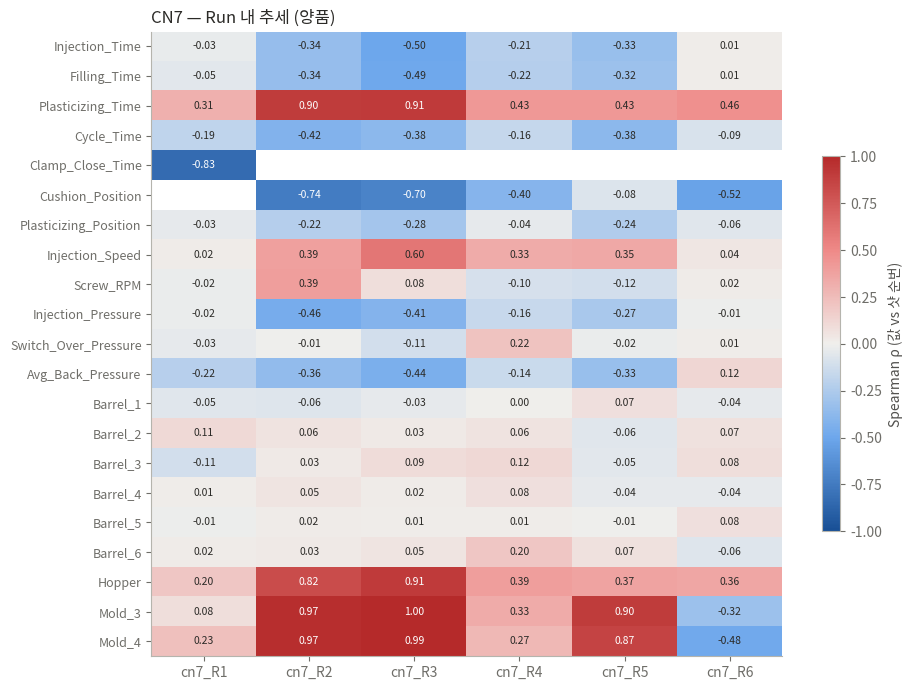

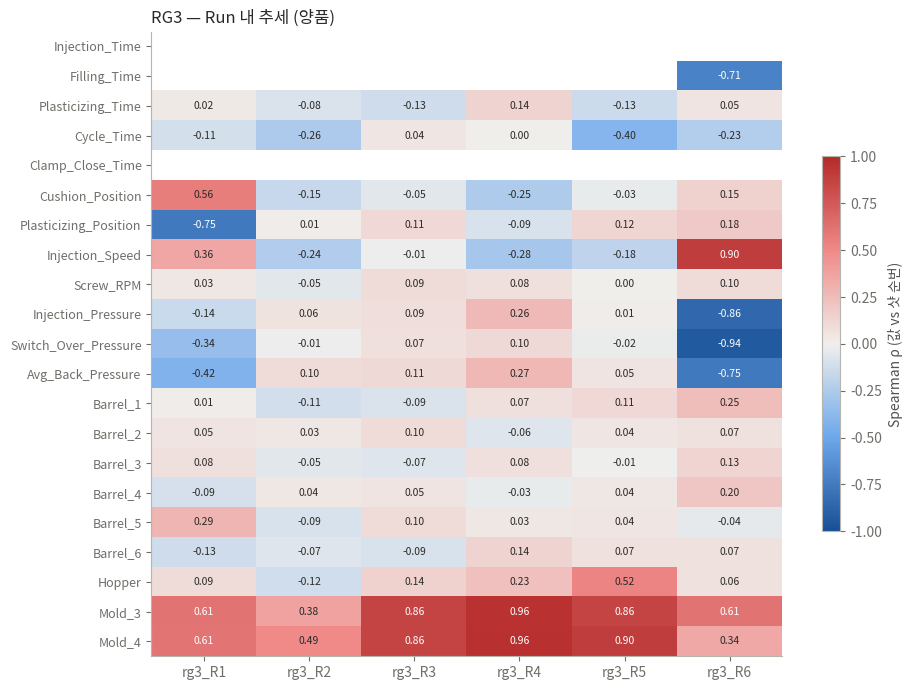

,제품,변수,|ρ|≥0.5 인 Run 수
1,CN7,Cushion_Position,3
4,CN7,Mold_Temperature_3,3
5,CN7,Mold_Temperature_4,3
2,CN7,Hopper_Temperature,2
6,CN7,Plasticizing_Time,2
0,CN7,Clamp_Close_Time,1
3,CN7,Max_Injection_Speed,1
14,RG3,Mold_Temperature_3,5
15,RG3,Mold_Temperature_4,4
7,RG3,Average_Back_Pressure,1


In [5]:
rows = []
for p in PRODUCTS:
    for r, g in D[p].groupby('run_id'):
        g = g[g['PassOrFail'] == 0]
        for v in VARS:
            x = g[raw(v)]
            rho = spearmanr(g['shot_seq_in_run'], x)[0] if x.nunique() >= 3 and len(g) >= 10 else np.nan
            rows.append({'제품': p.upper(), 'run_id': r, '변수': v, 'rho': rho, '샷': len(g)})
DRIFT = pd.DataFrame(rows)
DRIFT.to_csv(f'{OUT_DIR}/drift_table.csv', index=False, encoding='utf-8-sig')

for p in PRODUCTS:
    piv = DRIFT.query('제품 == @p.upper()').pivot(index='변수', columns='run_id', values='rho').loc[VARS]
    fig, ax = plt.subplots(figsize=(1.1 * piv.shape[1] + 3, 7))
    im = ax.imshow(piv.values, cmap=DIVERGING, vmin=-1, vmax=1, aspect='auto')
    ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns)
    ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels([short(v) for v in piv.index], fontsize=9)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            val = piv.values[i, j]
            if not np.isnan(val):
                ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=7.5,
                        color='white' if abs(val) > 0.6 else INK)
    ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.6, label='Spearman ρ (값 vs 샷 순번)')
    ax.set_title(f'{p.upper()} — Run 내 추세 (양품)', loc='left', color=INK)
    fig.tight_layout(); fig.savefig(f'{OUT_DIR}/drift_{p}.png', dpi=130); plt.show()

strong = (DRIFT.assign(abs_rho=DRIFT['rho'].abs()).query('abs_rho >= 0.5')
          .groupby(['제품', '변수']).size().rename('|ρ|≥0.5 인 Run 수').reset_index()
          .sort_values(['제품', '|ρ|≥0.5 인 Run 수'], ascending=[True, False]))
display(strong)

## 3. 불량의 시간 군집성 (순열검정)

- **통계량**: 같은 Run 안에서 ±k샷 이내에 다른 불량이 있는 불량 샷 수 (k = 1, 5)
- **귀무 분포**: 각 Run의 불량 수는 그대로 두고 Run 안에서 라벨 위치만 무작위로 섞기 × 5000회
- p < 0.05 → 불량이 우연보다 **몰려서** 발생 → 과거 샷의 상태가 현재 불량과 연관 (시계열 정보가 의미 있음)
- 초기허용불량(재가동 직후 연속 발생)이 결과를 좌우할 수 있어 **포함 / 제외** 두 가지로 본다

In [6]:
def neighbor_count(labels_by_run, k):
    total = 0
    for y in labels_by_run:
        idx = np.flatnonzero(y)
        if len(idx) < 2:
            continue
        dist = np.abs(idx[:, None] - idx[None, :]); np.fill_diagonal(dist, 10**9)
        total += int((dist.min(axis=1) <= k).sum())
    return total

def cluster_test(d, k, exclude_initial):
    dd = d[d['Reason'] != '초기허용불량'] if exclude_initial else d
    ys = [g['PassOrFail'].values.astype(int) for _, g in dd.groupby('run_id')]
    obs = neighbor_count(ys, k)
    null = np.empty(N_PERM)
    for i in range(N_PERM):
        null[i] = neighbor_count([RNG.permutation(y) for y in ys], k)
    return obs, null.mean(), (np.sum(null >= obs) + 1) / (N_PERM + 1), int(sum(y.sum() for y in ys))

rows = []
for p in PRODUCTS:
    for excl in [False, True]:
        if excl and (D[p]['Reason'] == '초기허용불량').sum() == 0:
            continue
        for k in [1, 5]:
            obs, exp, pval, nf = cluster_test(D[p], k, excl)
            rows.append({'제품': p.upper(), '초기허용불량': '제외' if excl else '포함', 'k(샷)': k, '불량 수': nf,
                         '관측(이웃 불량 있는 불량)': obs, '무작위 기대값': round(exp, 2), 'p값': pval,
                         '판정': '군집 있음' if pval < 0.05 else '군집 근거 없음'})
CLUSTER = pd.DataFrame(rows)
CLUSTER.to_csv(f'{OUT_DIR}/cluster_test.csv', index=False, encoding='utf-8-sig')
display(CLUSTER)

,제품,초기허용불량,k(샷),불량 수,관측(이웃 불량 있는 불량),무작위 기대값,p값,판정
0,CN7,포함,1,20,16,1.95,0.000200,군집 있음
1,CN7,포함,5,20,17,7.81,0.000400,군집 있음
2,CN7,제외,1,15,11,1.89,0.000400,군집 있음
3,CN7,제외,5,15,12,7.30,0.016997,군집 있음
4,RG3,포함,1,32,7,4.09,0.139972,군집 근거 없음
5,RG3,포함,5,32,16,14.26,0.340732,군집 근거 없음


In [7]:
# 참고: 직전 샷이 불량일 때 현재 샷 불량 확률 vs 기본 불량률
rows = []
for p in PRODUCTS:
    d = D[p].copy()
    d['prev_fail'] = d.groupby('run_id')['PassOrFail'].shift(1)
    d = d.dropna(subset=['prev_fail'])
    base = d['PassOrFail'].mean()
    cond = d.loc[d['prev_fail'] == 1, 'PassOrFail']
    rows.append({'제품': p.upper(), '기본 불량률': base, 'P(불량 | 직전 불량)': cond.mean() if len(cond) else np.nan,
                 '직전 불량 샷 수': len(cond), '배수(lift)': cond.mean() / base if len(cond) and base > 0 else np.nan})
display(pd.DataFrame(rows).style.format({'기본 불량률': '{:.1%}', 'P(불량 | 직전 불량)': '{:.1%}', '배수(lift)': '{:.1f}'}))

,제품,기본 불량률,P(불량 | 직전 불량),직전 불량 샷 수,배수(lift)
0,CN7,1.0%,70.0%,20,69.1
1,RG3,5.2%,15.6%,32,3.0


## 4. Run 내 위치별 불량률

- 재가동(정지 후) 몇 번째 샷인지(`shots_since_stop`)와 Run 안 상대 위치(앞 1/3 · 중간 · 뒤 1/3)별 불량률
- Fisher 정확검정: **재가동 후 1~5샷 vs 나머지**, **Run 앞 1/3 vs 나머지**

In [8]:
def fisher_row(mask, y):
    a = int(y[mask].sum()); b = int(mask.sum() - a); c = int(y[~mask].sum()); dd = int((~mask).sum() - c)
    return fisher_exact([[a, b], [c, dd]])[1], a / max(mask.sum(), 1), c / max((~mask).sum(), 1)

rows, tests = [], []
for p in PRODUCTS:
    d = D[p].copy()
    d['재가동 후'] = pd.cut(d['shots_since_stop'], [0, 5, 20, 50, np.inf], labels=['1~5', '6~20', '21~50', '51+'])
    d['rel'] = d.groupby('run_id')['shot_seq_in_run'].transform(lambda s: (s - 1) / max(s.max() - 1, 1))
    d['Run 내 위치'] = pd.cut(d['rel'], [-0.01, 1 / 3, 2 / 3, 1.0], labels=['앞 1/3', '중간', '뒤 1/3'])
    for col in ['재가동 후', 'Run 내 위치']:
        t = d.groupby(col, observed=True)['PassOrFail'].agg(['size', 'sum', 'mean']).reset_index()
        t.columns = ['구간', '샷', '불량', '불량률']; t.insert(0, '기준', col); t.insert(0, '제품', p.upper())
        rows.append(t)
    y = d['PassOrFail'].values
    for name, mask in [('재가동 후 1~5샷 vs 나머지', d['shots_since_stop'].values <= 5),
                       ('Run 앞 1/3 vs 나머지', d['rel'].values <= 1 / 3)]:
        for excl in [False, True]:
            m = (d['Reason'] != '초기허용불량').values if excl else np.ones(len(d), bool)
            if excl and m.all():
                continue
            pv, r1, r0 = fisher_row(mask[m], y[m])
            tests.append({'제품': p.upper(), '비교': name, '초기허용불량': '제외' if excl else '포함',
                          '해당 구간 불량률': r1, '나머지 불량률': r0, 'Fisher p': pv})
POSITION = pd.concat(rows, ignore_index=True)
POS_TEST = pd.DataFrame(tests)
POSITION.to_csv(f'{OUT_DIR}/position_table.csv', index=False, encoding='utf-8-sig')
POS_TEST.to_csv(f'{OUT_DIR}/position_test.csv', index=False, encoding='utf-8-sig')
display(POSITION.style.format({'불량률': '{:.1%}'}))
display(POS_TEST.style.format({'해당 구간 불량률': '{:.1%}', '나머지 불량률': '{:.1%}', 'Fisher p': '{:.4f}'}))

,제품,기준,구간,샷,불량,불량률
0,CN7,재가동 후,1~5,60,5,8.3%
1,CN7,재가동 후,6~20,166,0,0.0%
2,CN7,재가동 후,21~50,289,3,1.0%
3,CN7,재가동 후,51+,1464,12,0.8%
4,CN7,Run 내 위치,앞 1/3,662,19,2.9%
5,CN7,Run 내 위치,중간,657,1,0.2%
6,CN7,Run 내 위치,뒤 1/3,660,0,0.0%
7,RG3,재가동 후,1~5,40,1,2.5%
8,RG3,재가동 후,6~20,120,11,9.2%
9,RG3,재가동 후,21~50,180,9,5.0%


,제품,비교,초기허용불량,해당 구간 불량률,나머지 불량률,Fisher p
0,CN7,재가동 후 1~5샷 vs 나머지,포함,8.3%,0.8%,0.0002
1,CN7,재가동 후 1~5샷 vs 나머지,제외,0.0%,0.8%,1.0000
2,CN7,Run 앞 1/3 vs 나머지,포함,2.9%,0.1%,0.0000
3,CN7,Run 앞 1/3 vs 나머지,제외,2.1%,0.1%,0.0000
4,RG3,재가동 후 1~5샷 vs 나머지,포함,2.5%,5.3%,0.7134
5,RG3,Run 앞 1/3 vs 나머지,포함,5.2%,5.0%,1.0000


## 5. 이벤트 스터디 — 불량 전에 신호가 먼저 오나?

- **인과적 편차** `dev_t = (x_t − 직전 20샷 중앙값) / scale`, scale = max(1.4826·MAD, 기록 단위) — 같은 Run의 **과거 샷만** 사용 (실시간 계산 가능, 라벨 미사용)
- 불량 샷을 0으로 두고 −10 ~ +3샷의 |dev| 평균을 그린다. **0이 아닌 위치는 양품 샷만** 평균 (연속 불량끼리 서로의 '선행 신호'가 되는 것 방지). 대조군 = 같은 Run에서 무작위로 뽑은 양품 샷(불량과 ±10샷 이상 떨어진 곳)
- 해석
  - **0에서만 튐** → 그 샷에서 갑자기 생기는 이벤트형 (샷 직후 판단으로 충분)
  - **−1, −2, … 부터 올라감** → 선행 신호 존재 (다음 샷 위험 예측 / 조기경보 가능)
  - **대조군과 차이 없음** → 공정 변수의 시간 변화로는 설명 안 됨
- Run 시작 직후(과거 5샷 미만)는 dev가 NaN → 해당 lag는 평균에서 빠짐

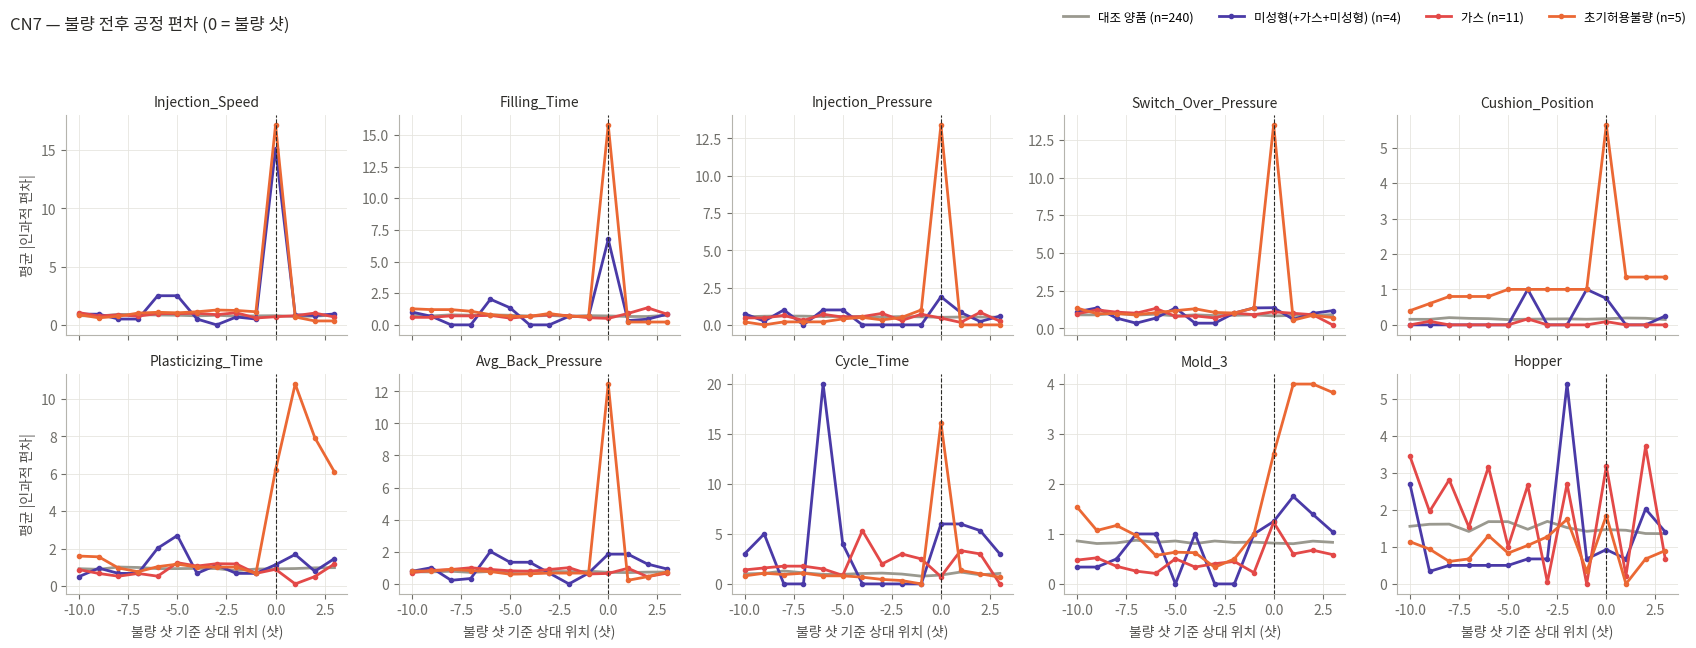

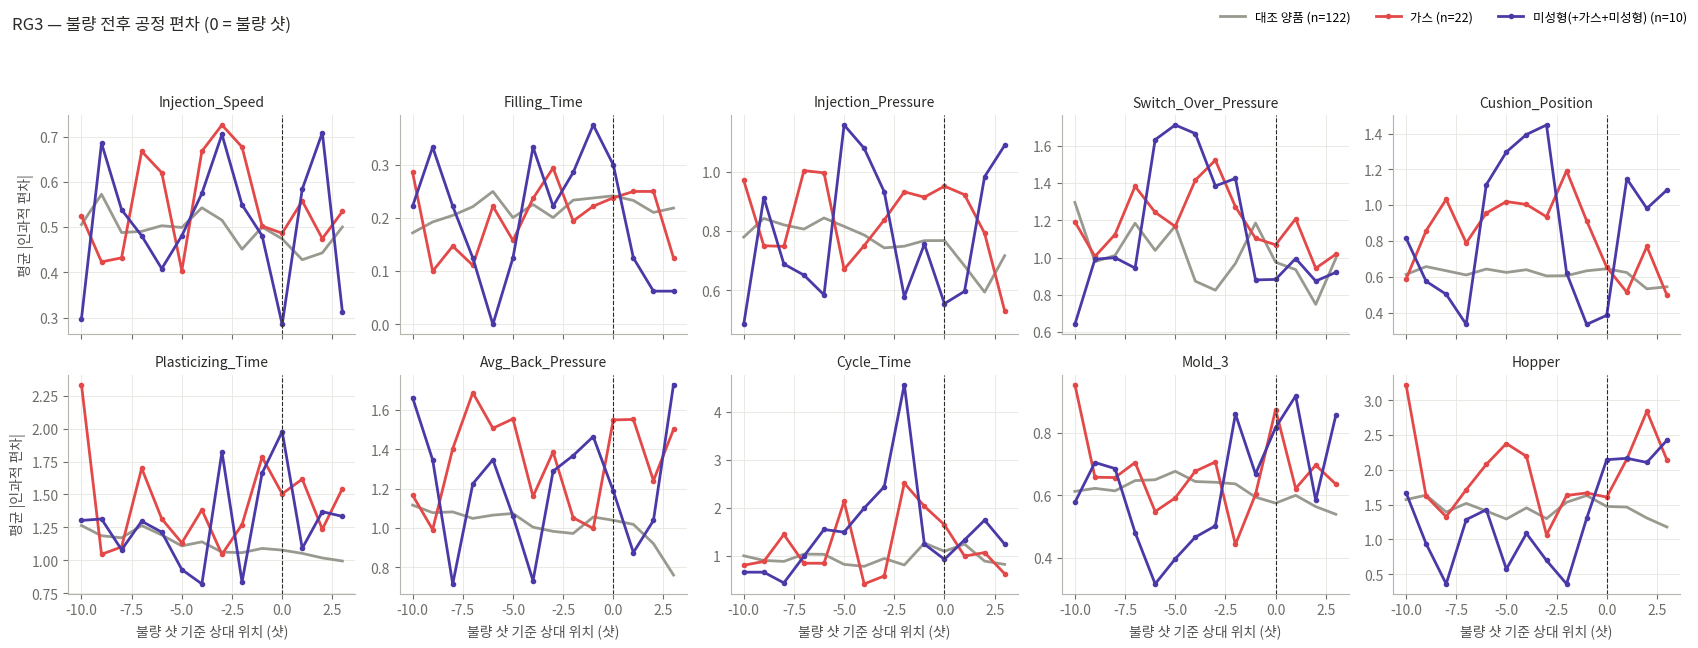

In [9]:
def causal_dev(d, col):
    out = pd.Series(np.nan, index=d.index)
    step = resolution(d[col])
    step = 1e-6 if np.isnan(step) else step
    for _, g in d.groupby('run_id'):
        x = g[col].astype(float)
        past = x.shift(1).rolling(W, min_periods=MINP)
        med = past.median()
        mad = past.apply(lambda a: np.median(np.abs(a - np.median(a))), raw=True) * 1.4826
        scale = np.maximum(mad.fillna(0).values, step)
        out.loc[g.index] = (x.values - med.values) / scale
    return out

EV_LAGS = list(range(-10, 4))
for p in PRODUCTS:
    d = D[p]
    for v in KEY:
        d[f'dev_{v}'] = causal_dev(d, raw(v))

def event_curve(d, centers, v):
    col = d[f'dev_{v}'].abs().clip(upper=20)   # 극단값 1~2개가 평균을 지배하지 않게 20에서 자름
    run = d['run_id'].values
    fail = d['PassOrFail'].values
    res = []
    for L in EV_LAGS:
        vals = []
        for i in centers:
            j = i + L
            # lag ≠ 0 에서는 양품 샷만 사용: 연속 불량이 '선행 신호'로 잘못 잡히는 것 방지
            if 0 <= j < len(d) and run[j] == run[i] and not np.isnan(col.iat[j]) and (L == 0 or fail[j] == 0):
                vals.append(col.iat[j])
        res.append(np.mean(vals) if vals else np.nan)
    return np.array(res)

def control_centers(d, n_per_run=40):
    out = []
    for _, g in d.groupby('run_id'):
        fail_pos = np.flatnonzero(g['PassOrFail'].values)
        idx = np.arange(len(g))
        ok = [i for i in idx if g['PassOrFail'].iat[i] == 0 and i >= MINP + 10 and
              (len(fail_pos) == 0 or np.min(np.abs(fail_pos - i)) > 10)]
        if ok:
            out += list(g.index[RNG.choice(ok, size=min(n_per_run, len(ok)), replace=False)])
    return out

GROUPS = {'cn7': {'미성형(+가스+미성형)': ['미성형', '가스+미성형'], '가스': ['가스'], '초기허용불량': ['초기허용불량']},
          'rg3': {'가스': ['가스'], '미성형(+가스+미성형)': ['미성형', '가스+미성형']}}
GCOL = {'미성형(+가스+미성형)': PURPLE, '가스': RED, '초기허용불량': ORANGE}
EV_ROWS = []
for p in PRODUCTS:
    d = D[p]
    ctrl = control_centers(d)
    fig, axes = plt.subplots(2, 5, figsize=(17, 6.5), sharex=True)
    for ax, v in zip(axes.flat, KEY):
        cc = event_curve(d, ctrl, v)
        ax.plot(EV_LAGS, cc, color=MUTED, lw=2, label=f'대조 양품 (n={len(ctrl)})')
        for gname, reasons in GROUPS[p].items():
            centers = list(d.index[d['Reason'].isin(reasons)])
            if not centers:
                continue
            ec = event_curve(d, centers, v)
            ax.plot(EV_LAGS, ec, color=GCOL[gname], lw=2, marker='o', ms=3, label=f'{gname} (n={len(centers)})')
            for L, e, c in zip(EV_LAGS, ec, cc):
                EV_ROWS.append({'제품': p.upper(), '변수': v, '불량군': gname, 'n': len(centers), 'lag': L,
                                '불량 |dev|': e, '대조 |dev|': c})
        ax.axvline(0, color=INK, lw=0.8, ls='--')
        ax.set_title(short(v), fontsize=10, color=INK)
    for ax in axes[1]: ax.set_xlabel('불량 샷 기준 상대 위치 (샷)')
    axes[0, 0].set_ylabel('평균 |인과적 편차|'); axes[1, 0].set_ylabel('평균 |인과적 편차|')
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper right', ncol=4, frameon=False, fontsize=9)
    fig.suptitle(f'{p.upper()} — 불량 전후 공정 편차 (0 = 불량 샷)', x=0.01, ha='left', color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.93)); fig.savefig(f'{OUT_DIR}/event_{p}.png', dpi=130); plt.show()

EVENT = pd.DataFrame(EV_ROWS)
EVENT.to_csv(f'{OUT_DIR}/event_table.csv', index=False, encoding='utf-8-sig')

In [10]:
# 요약: 불량 샷(0) / 직전 1~3샷 평균 / 대조군 — 각 불량군에서 가장 크게 벌어진 변수 기준
def summarize_event(EVENT):
    rows = []
    for (p, g, v), t in EVENT.groupby(['제품', '불량군', '변수']):
        t = t.set_index('lag')
        rows.append({'제품': p, '불량군': g, '변수': v, 'n': int(t['n'].iloc[0]),
                     'lag0 불량': t.loc[0, '불량 |dev|'], 'lag−3~−1 불량': t.loc[[-3, -2, -1], '불량 |dev|'].mean(),
                     '대조': t['대조 |dev|'].mean()})
    s = pd.DataFrame(rows)
    s['lag0 배수'] = s['lag0 불량'] / s['대조']
    s['선행 배수'] = s['lag−3~−1 불량'] / s['대조']
    return s
EV_SUM = summarize_event(EVENT)
top = EV_SUM.sort_values('lag0 배수', ascending=False).groupby(['제품', '불량군']).head(3)
display(top.style.format({c: '{:.2f}' for c in ['lag0 불량', 'lag−3~−1 불량', '대조', 'lag0 배수', '선행 배수']}))

,제품,불량군,변수,n,lag0 불량,lag−3~−1 불량,대조,lag0 배수,선행 배수
21,CN7,초기허용불량,Cushion_Position,5,5.64,1.00,0.17,33.11,5.88
25,CN7,초기허용불량,Max_Injection_Pressure,5,13.40,0.61,0.55,24.46,1.12
23,CN7,초기허용불량,Filling_Time,5,15.78,0.75,0.73,21.71,1.03
16,CN7,미성형(+가스+미성형),Max_Injection_Speed,4,15.12,0.39,0.80,18.88,0.49
13,CN7,미성형(+가스+미성형),Filling_Time,4,6.75,0.45,0.73,9.28,0.62
12,CN7,미성형(+가스+미성형),Cycle_Time,4,6.00,0.00,1.02,5.87,0.00
4,CN7,가스,Hopper_Temperature,11,3.17,0.91,1.52,2.09,0.60
49,RG3,미성형(+가스+미성형),Plasticizing_Time,10,1.98,1.44,1.12,1.76,1.29
32,RG3,가스,Cycle_Time,22,1.65,1.72,0.97,1.70,1.76
30,RG3,가스,Average_Back_Pressure,22,1.55,1.15,1.02,1.53,1.13


## 6. 종합 판정

자동 요약 규칙
- **공정값 연관**: lag1 ACF가 유의한 변수 수 (상수 제외)
- **상태 변화**: `느린 상태 변화` 판정 변수 + Run 내 |ρ| ≥ 0.5 가 2개 Run 이상인 변수
- **불량 군집**: k=5 순열검정 p < 0.05 (초기허용 포함/제외 각각)
- **위치 효과**: 재가동 후 1~5샷 Fisher p < 0.05
- **선행 신호**: lag −3~−1 평균 |dev| ≥ 대조의 1.5배인 변수가 있는 불량군 / **동시 신호**: lag0 ≥ 대조의 2배

In [11]:
rows = []
for p in PRODUCTS:
    P = p.upper()
    a = ACF_TABLE.query('제품 == @P')
    sig = a[a['판정'].isin(['짧은 관성', '느린 상태 변화'])]
    slow = a.query("판정 == '느린 상태 변화'")['변수'].map(short).tolist()
    dr = strong.query('제품 == @P and `|ρ|≥0.5 인 Run 수` >= 2')['변수'].map(short).tolist()
    rows.append({'제품': P, '항목': '1. 공정값 자기상관', '결과': f"{len(sig)}/{(a['판정'] != '상수').sum()}개 변수가 직전 샷과 유의한 상관"})
    per = a.query("판정 == '주기적 진동'").apply(lambda r: f"{short(r['변수'])}(주기 {int(r['주기(샷)'])}샷)", axis=1).tolist()
    rows.append({'제품': P, '항목': '1. 주기적 진동', '결과': ', '.join(per) or '없음'})
    rows.append({'제품': P, '항목': '1·2. 느린 상태 변화', '결과': f"ACF 지속: {', '.join(slow) or '없음'} / Run 내 추세(2개 Run 이상): {', '.join(dr) or '없음'}"})
    for _, r in CLUSTER.query('제품 == @P and `k(샷)` == 5').iterrows():
        rows.append({'제품': P, '항목': f"3. 불량 군집 (초기허용 {r['초기허용불량']})",
                     '결과': f"{r['판정']} (관측 {r['관측(이웃 불량 있는 불량)']} vs 기대 {r['무작위 기대값']}, p={r['p값']:.4f})"})
    for _, r in POS_TEST.query('제품 == @P and 비교.str.startswith("재가동")', engine='python').iterrows():
        rows.append({'제품': P, '항목': f"4. 재가동 직후 효과 (초기허용 {r['초기허용불량']})",
                     '결과': f"1~5샷 {r['해당 구간 불량률']:.1%} vs 나머지 {r['나머지 불량률']:.1%} (p={r['Fisher p']:.4f})"})
    for g, t in EV_SUM.query('제품 == @P').groupby('불량군'):
        lead = t.query('`선행 배수` >= 1.5')['변수'].map(short).tolist()
        same = t.query('`lag0 배수` >= 2')['변수'].map(short).tolist()
        rows.append({'제품': P, '항목': f"5. 이벤트 스터디: {g} (n={int(t['n'].iloc[0])})",
                     '결과': f"동시 신호: {', '.join(same) or '없음'} / 선행 신호: {', '.join(lead) or '없음'}"})
SUMMARY = pd.DataFrame(rows)
SUMMARY.to_csv(f'{OUT_DIR}/temporal_summary.csv', index=False, encoding='utf-8-sig')
with pd.option_context('display.max_colwidth', 200):
    display(SUMMARY)

,제품,항목,결과
0,CN7,1. 공정값 자기상관,13/21개 변수가 직전 샷과 유의한 상관
1,CN7,1. 주기적 진동,"Injection_Time(주기 10샷), Filling_Time(주기 10샷), Injection_Pressure(주기 10샷), Switch_Over_Pressure(주기 20샷), Avg_Back_Pressure(주기 10샷), Barrel_4(주기 10샷)"
2,CN7,1·2. 느린 상태 변화,"ACF 지속: Plasticizing_Time, Clamp_Close_Time, Cushion_Position, Hopper, Mold_3, Mold_4 / Run 내 추세(2개 Run 이상): Cushion_Position, Mold_3, Mold_4, Hopper, Plasticizing_Time"
3,CN7,3. 불량 군집 (초기허용 포함),"군집 있음 (관측 17 vs 기대 7.81, p=0.0004)"
4,CN7,3. 불량 군집 (초기허용 제외),"군집 있음 (관측 12 vs 기대 7.3, p=0.0170)"
5,CN7,4. 재가동 직후 효과 (초기허용 포함),1~5샷 8.3% vs 나머지 0.8% (p=0.0002)
6,CN7,4. 재가동 직후 효과 (초기허용 제외),1~5샷 0.0% vs 나머지 0.8% (p=1.0000)
7,CN7,5. 이벤트 스터디: 가스 (n=11),동시 신호: Hopper / 선행 신호: Cycle_Time
8,CN7,5. 이벤트 스터디: 미성형(+가스+미성형) (n=4),"동시 신호: Avg_Back_Pressure, Cushion_Position, Cycle_Time, Filling_Time, Injection_Pressure, Injection_Speed / 선행 신호: Cushion_Position"
9,CN7,5. 이벤트 스터디: 초기허용불량 (n=5),"동시 신호: Avg_Back_Pressure, Cushion_Position, Cycle_Time, Filling_Time, Injection_Pressure, Injection_Speed, Switch_Over_Pressure, Mold_3, Plasticizing_Time / 선행 신호: Cushion_Position, Injection_Speed"


### 읽는 법 / 주의
- **n이 작다**: CN7 미성형 4, 초기허용 5, RG3 불량 32 수준 → 이벤트 스터디 곡선은 경향 확인용이며 통계적 확정은 3·4장 검정으로 판단
- **인과적 편차는 과거 샷만** 사용하므로 그대로 모델 파생변수로 쓸 수 있다 (라벨·미래 정보 없음). 단 연속 불량이 기준선(직전 20샷)에 섞이면 편차가 작아질 수 있음 → 04_features에서 |dev|>5 샷을 기준선에서 빼는 보완 예정
- 순열검정은 **Run 안에서만** 섞는다 → Run별 불량률 차이(상태형)는 귀무가설에 이미 포함. 즉 "Run 안에서도 몰려 있는가"를 본다
- 결론 연결: 1·2 → 상태형 파생변수(rolling 평균, 추세) 근거 / 3·4 → shots_since_stop 등 위치 변수 근거 / 5 → 샷 직후 판단으로 충분한지, 조기경보가 가능한지